In [1]:
import json
from pathlib import Path

import pandas as pd
import matplotlib.pyplot as plt

result_dirs = {"Mel": Path("../model_for_mel/models"), "Mfcc": Path("../model_for_mfcc/models"),}

In [2]:
rows = []

for feature_type, model_dir in result_dirs.items():
    # feature_type = Mel, model_dir = "model_for_mel/models"
    # feature_type = Mfcc, model_dir = ...
    for result_path in model_dir.glob("*/results.json"):# get all results file
        with open(result_path, "r", encoding="utf-8") as f:
            result = json.load(f)

        # skip mini evaluation runs
        if result.get("use_mini_evaluation") is True:
            continue

        train_split = result["train_split_name"] # 0.25, 0.5, 0.75, 1
        train_size = int(train_split.replace("train_", "")) / 100

        rows.append({
            "feature_type": feature_type,
            "train_size": train_size,
            "test_accuracy": result["test_accuracy"],
            "val_loss": result["best_validation_loss"],
        })

df = pd.DataFrame(rows)

df = df.sort_values(["feature_type", "train_size"]).reset_index(drop=True)

print(df)

  feature_type  train_size  test_accuracy  val_loss
0          Mel        0.25       0.579122  1.588039
1          Mel        0.50       0.589468  1.523804
2          Mel        0.75       0.595128  1.487781
3          Mel        1.00       0.598969  1.474163
4         Mfcc        0.25       0.617257  1.341886
5         Mfcc        0.50       0.618958  1.324048
6         Mfcc        0.75       0.621963  1.328758
7         Mfcc        1.00       0.623009  1.322676


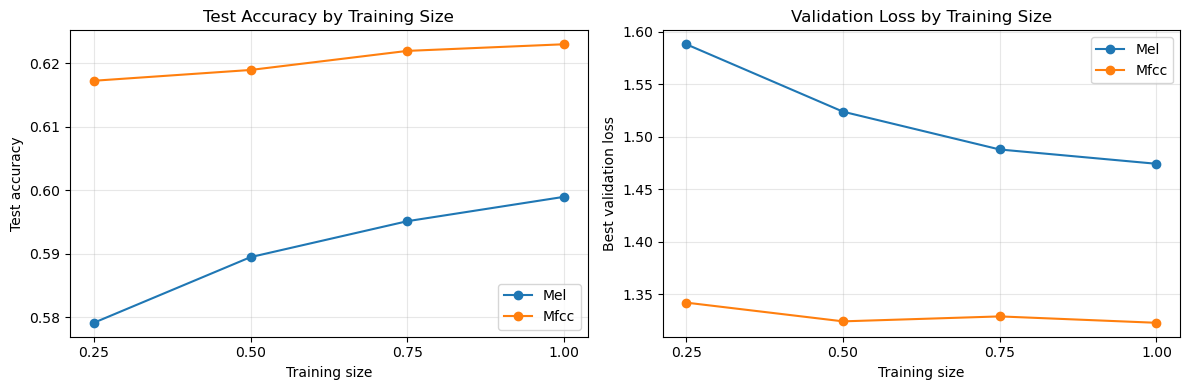

In [3]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))

for feature_type in ["Mel", "Mfcc"]:
    subset = df[df["feature_type"] == feature_type]

    axes[0].plot(
        subset["train_size"],
        subset["test_accuracy"],
        marker="o",
        label=feature_type
    )

    axes[1].plot(
        subset["train_size"],
        subset["val_loss"],
        marker="o",
        label=feature_type
    )

axes[0].set_title("Test Accuracy by Training Size")
axes[0].set_xlabel("Training size")
axes[0].set_ylabel("Test accuracy")
axes[0].set_xticks([0.25, 0.50, 0.75, 1.00])
axes[0].legend()
axes[0].grid(alpha=0.3)

axes[1].set_title("Validation Loss by Training Size")
axes[1].set_xlabel("Training size")
axes[1].set_ylabel("Best validation loss")
axes[1].set_xticks([0.25, 0.50, 0.75, 1.00])
axes[1].legend()
axes[1].grid(alpha=0.3)

plt.savefig("Test_Acc_and_Val_Loss_DiffFeat.png", dpi=300, bbox_inches="tight")
plt.tight_layout()
plt.show()

In [4]:
rows = []

for feature_type, model_dir in result_dirs.items():
    for pause_path in model_dir.glob("*/evaluation/pause_data.json"):
        run_dir = pause_path.parents[1]
        results_path = run_dir / "results.json"

        with open(pause_path, "r", encoding="utf-8") as f:
            pause_data = json.load(f)

        with open(results_path, "r", encoding="utf-8") as f:
            results = json.load(f)

        if results.get("use_mini_evaluation") is True:
            continue

        train_split = results["train_split_name"]
        train_size = int(train_split.replace("train_", "")) / 100

        rows.append({
            "feature_type": feature_type,
            "train_split": train_split,
            "train_size": train_size,
            "accuracy_without_pause": pause_data["accuracy_without_pause"]
        })

df = pd.DataFrame(rows)
df = df.sort_values(["feature_type", "train_size"])

print(df)

  feature_type train_split  train_size  accuracy_without_pause
2          Mel    train_25        0.25                0.278554
0          Mel    train_50        0.50                0.298809
3          Mel    train_75        0.75                0.310145
1          Mel   train_100        1.00                0.316367
5         Mfcc    train_25        0.25                0.355023
4         Mfcc    train_50        0.50                0.356530
6         Mfcc    train_75        0.75                0.363500
7         Mfcc   train_100        1.00                0.361687


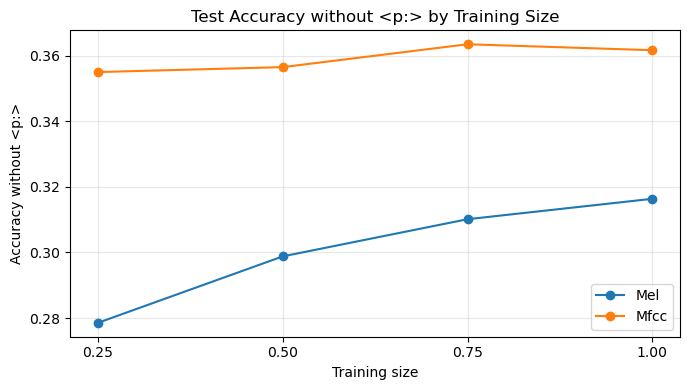

In [5]:
plt.figure(figsize=(7, 4))

for feature_type in ["Mel", "Mfcc"]:
    subset = df[df["feature_type"] == feature_type]

    plt.plot(
        subset["train_size"],
        subset["accuracy_without_pause"],
        marker="o",
        label=feature_type
    )

plt.title("Test Accuracy without <p:> by Training Size")
plt.xlabel("Training size")
plt.ylabel("Accuracy without <p:>")
plt.xticks([0.25, 0.50, 0.75, 1.00])
plt.legend()
plt.grid(alpha=0.3)


plt.savefig("Test_Acc_No_Pause_DiffFeat.png", dpi=300, bbox_inches="tight")
plt.tight_layout()
plt.show()